In [11]:
import numpy as np
data = np.random.randn(1000)
data.mean(), data.std()

(np.float64(0.06806530909812855), np.float64(1.0268464740347791))

%timeit runs the code many times and averages. %%time runs it once. Use %timeit for microbenchmarks, %%time for training runs.

In [12]:
import numpy as np

%timeit np.random.randn(10000)


247 µs ± 5.73 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


In [13]:
%%time
np.random.randn(10000)

CPU times: user 734 µs, sys: 0 ns, total: 734 µs
Wall time: 436 µs


array([ 1.10700297, -0.11046093, -0.13052435, ...,  1.23935487,
        0.71573603,  1.32041644])

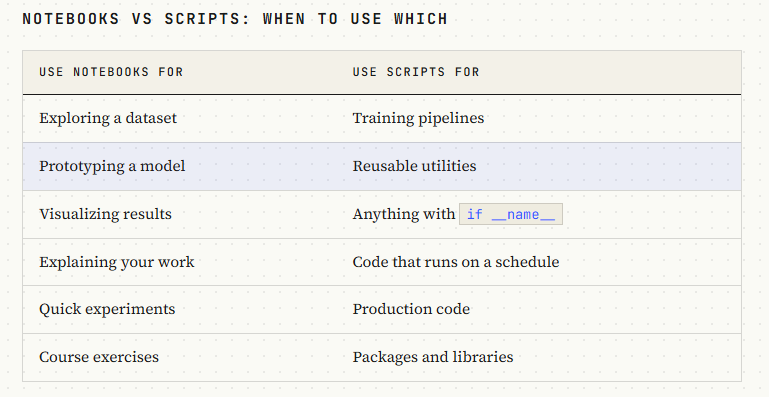

Exercises

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Enable inline plots in your notebook
%matplotlib inline

# Load the CSV file
df = pd.read_csv("sample_metrics.csv")

# Display the first few rows of the dataframe
display(df.head())

# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(pd.to_datetime(df["Date"]), df["Revenue"], marker="o", linestyle="-", color="#2b5b84", label="Revenue ($)")
plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'sample_metrics.csv'

In [ ]:
import time
import sys

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd


def timing_comparison():
    print("=== Timing: List vs NumPy ===\n")

    size = 1_000_000

    start = time.perf_counter()
    python_list = [x ** 2 for x in range(size)]
    list_time = time.perf_counter() - start
    print(f"List comprehension: {list_time:.4f}s")

    start = time.perf_counter()
    numpy_array = np.arange(size) ** 2
    numpy_time = time.perf_counter() - start
    print(f"NumPy:              {numpy_time:.4f}s")
    print(f"Speedup:            {list_time / numpy_time:.1f}x")


def inline_plotting():
    print("\n=== Inline Plotting ===\n")

    np.random.seed(42)
    x = np.linspace(0, 10, 200)
    y_sin = np.sin(x)
    y_noisy = y_sin + np.random.normal(0, 0.2, 200)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(x, y_sin, label="sin(x)")
    axes[0].plot(x, y_noisy, alpha=0.5, label="noisy")
    axes[0].set_title("Signal vs Noise")
    axes[0].legend()

    axes[1].hist(y_noisy - y_sin, bins=30, edgecolor="black")
    axes[1].set_title("Noise Distribution")

    plt.tight_layout()
    #plt.savefig("notebook_plot.png", dpi=100)
    plt.show()
    print("Saved plot to notebook_plot.png")
    print("In a notebook, plt.show() displays this inline.")


def dataframe_display():
    print("\n=== DataFrame Display ===\n")

    df = pd.DataFrame({
        "model": ["Linear Regression", "Random Forest", "Neural Network", "XGBoost"],
        "accuracy": [0.72, 0.89, 0.94, 0.91],
        "train_time_sec": [0.1, 2.3, 45.6, 8.2],
        "parameters": [102, 50_000, 1_200_000, 25_000],
    })

    print("In a notebook, just typing 'df' renders a rich HTML table:\n")
    print(df.to_string(index=False))

    print(f"\nBest model: {df.loc[df['accuracy'].idxmax(), 'model']}")
    print(f"Fastest model: {df.loc[df['train_time_sec'].idxmin(), 'model']}")


def memory_check():
    print("\n=== Memory Usage ===\n")

    small = np.random.randn(1000)
    medium = np.random.randn(100_000)
    large = np.random.randn(10_000_000)

    for name, arr in [("1K", small), ("100K", medium), ("10M", large)]:
        size_mb = arr.nbytes / 1e6
        print(f"Array {name:>4s} elements: {size_mb:>8.2f} MB")

    print(f"\nPython process memory: ~{sys.getsizeof(large) / 1e6:.1f} MB for the large array")
    print("In notebooks, memory accumulates across cells. Restart the kernel to free it.")


def magic_command_equivalents():
    print("\n=== Magic Command Equivalents ===\n")
    print("In a notebook, you would use magic commands:")
    print("  %timeit np.random.randn(10000)    -> micro-benchmark")
    print("  %%time long_operation()            -> wall clock time")
    print("  %matplotlib inline                 -> show plots in cells")
    print("  !pip install package               -> install from notebook")
    print("  %env VAR                           -> check env variable")
    print()

    iterations = 1000
    start = time.perf_counter()
    for _ in range(iterations):
        np.random.randn(10000)
    elapsed = time.perf_counter() - start
    per_call = elapsed / iterations * 1e6

    print(f"Manual timing (like %%timeit): np.random.randn(10000)")
    print(f"  {per_call:.1f} us per call ({iterations} iterations)")


if __name__ == "__main__":
    print("Notebook Tips - Key Patterns\n")
    print("Run these in a Jupyter notebook to see rich output.\n")

    timing_comparison()
    inline_plotting()
    dataframe_display()
    memory_check()
    magic_command_equivalents()


Notebook Tips - Key Patterns

Run these in a Jupyter notebook to see rich output.

=== Timing: List vs NumPy ===

List comprehension: 0.0829s
NumPy:              0.0049s
Speedup:            17.0x

=== Inline Plotting ===

Saved plot to notebook_plot.png
In a notebook, plt.show() displays this inline.

=== DataFrame Display ===

In a notebook, just typing 'df' renders a rich HTML table:

            model  accuracy  train_time_sec  parameters
Linear Regression      0.72             0.1         102
    Random Forest      0.89             2.3       50000
   Neural Network      0.94            45.6     1200000
          XGBoost      0.91             8.2       25000

Best model: Neural Network
Fastest model: Linear Regression

=== Memory Usage ===

Array   1K elements:     0.01 MB
Array 100K elements:     0.80 MB
Array  10M elements:    80.00 MB

Python process memory: ~80.0 MB for the large array
In notebooks, memory accumulates across cells. Restart the kernel to free it.

=== Magic Comma